# FedVocabHAR PAMAP2 Phase 4A — common-protocol vocabulary repair

## Third-dataset acquisition, audit, and confirmatory preregistration

Phase 4A prepares PAMAP2 as the third and genuinely independent dataset for OpenFedHAR. The official UCI download contains a nested `PAMAP2_Dataset.zip`; this repaired version reuses that extracted archive. It uses the eight subjects with complete protocol coverage and a common eight-activity vocabulary, then extracts the hand-mounted 16 g accelerometer, creates 50 Hz XYZ-plus-magnitude windows, audits coverage, and writes the fixed ranked-MNN policy lock before any Phase 4B test results are opened.

PAMAP2 is intentionally not used to redesign the method. The Phase 3D ranked-MNN policy, calibration quantiles, and four-query budget are copied verbatim into the Phase 4A manifest.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from dataclasses import dataclass,asdict
from io import BytesIO
from pathlib import Path
import hashlib,json,shutil,time,zipfile,warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

warnings.filterwarnings('ignore')
@dataclass(frozen=True)
class Config:
    project:str='/content/drive/MyDrive/FedVocabHAR'
    official_url:str='https://archive.ics.uci.edu/static/public/231/pamap2+physical+activity+monitoring.zip'
    subjects:tuple=(101,102,103,104,105,106,107,108)
    activity_map:tuple=((1,'lying'),(2,'sitting'),(3,'standing'),(4,'walking'),(12,'ascending_stairs'),(13,'descending_stairs'),(16,'vacuum_cleaning'),(17,'ironing'))
    known_activities:tuple=('lying','sitting','standing','walking')
    novel_activities:tuple=('ascending_stairs','descending_stairs','vacuum_cleaning','ironing')
    target_hz:int=50
    window_size:int=128
    stride:int=64
    gap_seconds:float=.10
    minimum_windows_per_subject_activity:int=20
    request_timeout_seconds:int=240
    request_retries:int=4

CFG=Config();PROJECT=Path(CFG.project);DATA=PROJECT/'data'/'pamap2';RAW=DATA/'raw';CACHE=DATA/'cache';OUT=PROJECT/'artifacts'/'phase4a_fixed3';P3D=PROJECT/'artifacts'/'phase3d'
for p in (RAW,CACHE,OUT):p.mkdir(parents=True,exist_ok=True)
POLICY_LOCK=P3D/'phase3d_policy_lock.json';assert POLICY_LOCK.exists();policy_lock=json.loads(POLICY_LOCK.read_text());assert policy_lock['selected_policy']=='ranked_mnn'
print(json.dumps(asdict(CFG),indent=2));print('locked policy:',policy_lock['selected_policy']);print('free /content GB:',round(shutil.disk_usage('/content').free/2**30,2))


{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "official_url": "https://archive.ics.uci.edu/static/public/231/pamap2+physical+activity+monitoring.zip",
  "subjects": [
    101,
    102,
    103,
    104,
    105,
    106,
    107,
    108
  ],
  "activity_map": [
    [
      1,
      "lying"
    ],
    [
      2,
      "sitting"
    ],
    [
      3,
      "standing"
    ],
    [
      4,
      "walking"
    ],
    [
      12,
      "ascending_stairs"
    ],
    [
      13,
      "descending_stairs"
    ],
    [
      16,
      "vacuum_cleaning"
    ],
    [
      17,
      "ironing"
    ]
  ],
  "known_activities": [
    "lying",
    "sitting",
    "standing",
    "walking"
  ],
  "novel_activities": [
    "ascending_stairs",
    "descending_stairs",
    "vacuum_cleaning",
    "ironing"
  ],
  "target_hz": 50,
  "window_size": 128,
  "stride": 64,
  "gap_seconds": 0.1,
  "minimum_windows_per_subject_activity": 20,
  "request_timeout_seconds": 240,
  "request_retries": 4
}
lock

## Confirmatory manifest and subject roles

Each fold holds out two subjects. The other six are divided into two encoder-training, two checkpoint-selection, and two unlabeled integration clients. The two integration clients are sufficient for the locked mutual-nearest-neighbor agreement rule. The test subjects are never included in Phase 4B training, policy selection, calibration, or vocabulary promotion.


In [3]:
OUTER_TEST=((101,105),(102,106),(103,107),(104,108))
folds=[]
for fold_id,test in enumerate(OUTER_TEST,1):
    remaining=[s for s in CFG.subjects if s not in test]
    folds.append({'fold':fold_id,'train_subjects':remaining[:2],'selection_subjects':remaining[2:4],'integration_subjects':remaining[4:6],'test_subjects':list(test)})
for fold in folds:
    roles=[set(fold[k]) for k in ('train_subjects','selection_subjects','integration_subjects','test_subjects')]
    assert set.union(*roles)==set(CFG.subjects) and all(roles[i].isdisjoint(roles[j]) for i in range(4) for j in range(i+1,4))
manifest={'phase':'Phase 4A','dataset':'PAMAP2 Physical Activity Monitoring','official_source':CFG.official_url,'sensor':'hand 16 g accelerometer XYZ plus magnitude','sampling_hz':CFG.target_hz,'window':{'samples':CFG.window_size,'stride':CFG.stride},'known_activities':list(CFG.known_activities),'novel_activities':list(CFG.novel_activities),'outer_folds':folds,'locked_phase3d_policy':policy_lock,'rule':'The ranked-MNN policy, its calibration quantiles, and label-query budget are frozen. PAMAP2 may not be used to redesign or select the policy.'}
(OUT/'phase4a_preregistered_manifest.json').write_text(json.dumps(manifest,indent=2));print(json.dumps(manifest,indent=2))


{
  "phase": "Phase 4A",
  "dataset": "PAMAP2 Physical Activity Monitoring",
  "official_source": "https://archive.ics.uci.edu/static/public/231/pamap2+physical+activity+monitoring.zip",
  "sensor": "hand 16 g accelerometer XYZ plus magnitude",
  "sampling_hz": 50,
  "window": {
    "samples": 128,
    "stride": 64
  },
  "known_activities": [
    "lying",
    "sitting",
    "standing",
    "walking"
  ],
  "novel_activities": [
    "ascending_stairs",
    "descending_stairs",
    "vacuum_cleaning",
    "ironing"
  ],
  "outer_folds": [
    {
      "fold": 1,
      "train_subjects": [
        102,
        103
      ],
      "selection_subjects": [
        104,
        106
      ],
      "integration_subjects": [
        107,
        108
      ],
      "test_subjects": [
        101,
        105
      ]
    },
    {
      "fold": 2,
      "train_subjects": [
        101,
        103
      ],
      "selection_subjects": [
        104,
        105
      ],
      "integration_subjects": [


## Resumable official acquisition

The notebook uses the official UCI archive. A SHA-256 digest and archive member inventory are saved for reproducibility. Existing valid downloads are reused.


In [4]:
ARCHIVE=RAW/'pamap2_official.zip'
INNER_ARCHIVE=RAW/'PAMAP2_Dataset.zip'
def normalized_member(member):return member.replace('\\','/').lower()
def digest(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda:f.read(2**20),b''):h.update(block)
    return h.hexdigest()
def download():
    if ARCHIVE.exists() and ARCHIVE.stat().st_size>100000:
        try:
            with zipfile.ZipFile(ARCHIVE) as z:z.testzip()
            return 'cached'
        except Exception:ARCHIVE.unlink()
    tmp=ARCHIVE.with_suffix('.part')
    for attempt in range(1,CFG.request_retries+1):
        try:
            with requests.get(CFG.official_url,stream=True,timeout=CFG.request_timeout_seconds,headers={'User-Agent':'FedVocabHAR research downloader/1.0'}) as r:
                r.raise_for_status()
                with tmp.open('wb') as f:
                    for chunk in r.iter_content(2**20):
                        if chunk:f.write(chunk)
            tmp.replace(ARCHIVE)
            with zipfile.ZipFile(ARCHIVE) as z:assert z.testzip() is None
            return 'downloaded'
        except Exception:
            if tmp.exists():tmp.unlink()
            if attempt==CFG.request_retries:raise
            time.sleep(2**attempt)
status=download()
with zipfile.ZipFile(ARCHIVE) as outer:
    outer_members=outer.namelist();nested=[m for m in outer_members if normalized_member(m).endswith('pamap2_dataset.zip')]
    if nested and not INNER_ARCHIVE.exists():
        with outer.open(nested[0]) as source,INNER_ARCHIVE.open('wb') as target:shutil.copyfileobj(source,target,length=2**20)
DATA_ARCHIVE=INNER_ARCHIVE if INNER_ARCHIVE.exists() else ARCHIVE
with zipfile.ZipFile(DATA_ARCHIVE) as z:
    members=z.namelist();normalized={m:normalized_member(m) for m in members}
    protocol=[m for m,n in normalized.items() if n.endswith('.dat') and '/protocol/' in f'/{n.strip("/")}/' and any(n.endswith(f'subject{s}.dat') for s in CFG.subjects)]
record={'url':CFG.official_url,'status':status,'outer_path':str(ARCHIVE),'outer_bytes':ARCHIVE.stat().st_size,'outer_sha256':digest(ARCHIVE),'nested_member':nested[0] if nested else None,'data_path':str(DATA_ARCHIVE),'data_bytes':DATA_ARCHIVE.stat().st_size,'protocol_members':protocol}
(OUT/'phase4a_download_manifest.json').write_text(json.dumps(record,indent=2));print(json.dumps({'status':status,'outer_bytes':record['outer_bytes'],'nested_member':record['nested_member'],'data_bytes':record['data_bytes'],'protocol_files':len(protocol),'member_examples':members[:10]},indent=2))
assert len(protocol)>=len(CFG.subjects)


{
  "status": "cached",
  "outer_bytes": 688226940,
  "nested_member": "PAMAP2_Dataset.zip",
  "data_bytes": 688167640,
  "protocol_files": 8,
  "member_examples": [
    "PAMAP2_Dataset/Protocol/subject101.dat",
    "PAMAP2_Dataset/Protocol/subject102.dat",
    "PAMAP2_Dataset/Protocol/subject103.dat",
    "PAMAP2_Dataset/Protocol/subject104.dat",
    "PAMAP2_Dataset/Protocol/subject105.dat",
    "PAMAP2_Dataset/Protocol/subject106.dat",
    "PAMAP2_Dataset/Protocol/subject107.dat",
    "PAMAP2_Dataset/Protocol/subject108.dat",
    "PAMAP2_Dataset/Protocol/subject109.dat",
    "PAMAP2_Dataset/Optional/subject101.dat"
  ]
}


## Hand-accelerometer parsing and window cache

PAMAP2 protocol files are whitespace-delimited. Columns 5–7 contain the hand 16 g accelerometer axes. Activity-ID 0 is excluded. Each subject/activity sequence is split at timing gaps before 50 Hz interpolation, so no window crosses an unrecorded interval or activity boundary.


In [5]:
ACTIVITY=dict(CFG.activity_map);needed=set(ACTIVITY);raw_windows=[];window_subject=[];window_activity=[];window_segment=[];window_start=[];inventory=[];failures=[]
def protocol_member(subject):
    with zipfile.ZipFile(DATA_ARCHIVE) as z:
        matches=[m for m in z.namelist() if normalized_member(m).endswith(f'subject{subject}.dat') and '/protocol/' in f'/{normalized_member(m).strip("/")}/']
    if len(matches)!=1:raise RuntimeError(f'expected one Protocol file for {subject}, found {matches}; inspect phase4a_download_manifest.json')
    return matches[0]
def segments(frame):
    split=np.where(np.diff(frame.timestamp.values)>CFG.gap_seconds)[0]+1
    return np.split(frame,np.r_[0,split,len(frame)])[1:]
for subject in CFG.subjects:
    try:
        member=protocol_member(subject)
        with zipfile.ZipFile(DATA_ARCHIVE) as z:
            with z.open(member) as f:frame=pd.read_csv(f,sep=r'\s+',header=None,usecols=[0,1,4,5,6],names=['timestamp','activity_id','x','y','z'])
        frame=frame[frame.activity_id.isin(needed)].copy();frame['activity']=frame.activity_id.map(ACTIVITY)
        for activity in CFG.known_activities+CFG.novel_activities:
            part=frame[frame.activity==activity].drop(columns=['activity']).dropna().sort_values('timestamp')
            total=0;segment_id=0
            for seg in segments(part):
                if len(seg)<2:continue
                target=np.arange(seg.timestamp.iloc[0],seg.timestamp.iloc[-1]+1e-9,1/CFG.target_hz)
                if len(target)<CFG.window_size:continue
                values=np.stack([np.interp(target,seg.timestamp.values,seg[c].values) for c in ('x','y','z')],0).astype(np.float32)
                for start in range(0,len(target)-CFG.window_size+1,CFG.stride):
                    xyz=values[:,start:start+CFG.window_size];mag=np.sqrt((xyz*xyz).sum(0,keepdims=True)+1e-8);raw_windows.append(np.concatenate([xyz,mag],0));window_subject.append(subject);window_activity.append(activity);window_segment.append(segment_id);window_start.append(float(target[start]));total+=1
                segment_id+=1
            inventory.append({'subject':subject,'activity':activity,'raw_rows':len(part),'segments':segment_id,'windows':total,'member':member})
            print('processed',subject,activity,'windows',total)
    except Exception as e:failures.append({'subject':subject,'error':repr(e)})
if failures:
    pd.DataFrame(failures).to_csv(OUT/'phase4a_parse_failures.csv',index=False);raise RuntimeError(f'{len(failures)} subject files failed parsing')
x=np.asarray(raw_windows,dtype=np.float32);subjects=np.asarray(window_subject,dtype=np.int16);activities=np.asarray(window_activity);segments_id=np.asarray(window_segment,dtype=np.int16);starts=np.asarray(window_start,dtype=np.float32);inventory=pd.DataFrame(inventory);inventory.to_csv(OUT/'phase4a_recording_inventory.csv',index=False)
np.savez_compressed(CACHE/'pamap2_hand_acc_common8_w128_s64_50hz.npz',x=x,subject=subjects,activity=activities,segment=segments_id,start_seconds=starts,channels=np.asarray(['acc_x','acc_y','acc_z','acc_magnitude']))
print('cache:',x.shape)


processed 101 lying windows 211
processed 101 sitting windows 182
processed 101 standing windows 166
processed 101 walking windows 172
processed 101 ascending_stairs windows 121
processed 101 descending_stairs windows 113
processed 101 vacuum_cleaning windows 178
processed 101 ironing windows 183
processed 102 lying windows 182
processed 102 sitting windows 173
processed 102 standing windows 198
processed 102 walking windows 251
processed 102 ascending_stairs windows 133
processed 102 descending_stairs windows 115
processed 102 vacuum_cleaning windows 160
processed 102 ironing windows 224
processed 103 lying windows 171
processed 103 sitting windows 223
processed 103 standing windows 159
processed 103 walking windows 225
processed 103 ascending_stairs windows 78
processed 103 descending_stairs windows 116
processed 103 vacuum_cleaning windows 157
processed 103 ironing windows 217
processed 104 lying windows 179
processed 104 sitting windows 198
processed 104 standing windows 192
proces

## Quality audit and Phase 4B decision

Phase 4B may begin only when all nine subjects and all eight activities have sufficient windows, the cache round trip is exact, and the preregistered folds remain disjoint. A failure is a dataset feasibility finding; it does not permit changing the locked ranked-MNN policy.


activity,lying,sitting,standing,walking,ascending_stairs,descending_stairs,vacuum_cleaning,ironing
subject,,,,,,,,
101,211,182,166,172,121,113,178,183
102,182,173,198,251,133,115,160,224
103,171,223,159,225,78,116,157,217
104,179,198,192,243,127,109,155,194
105,183,207,171,246,108,96,189,255
106,181,179,189,199,101,85,163,290
107,199,92,200,260,135,88,167,229
108,187,177,195,243,89,72,188,254


{
  "phase": "Phase 4A",
  "dataset": "PAMAP2 common-protocol subset",
  "gates": {
    "G1_all_eight_subjects_present": true,
    "G2_all_eight_activities_present": true,
    "G3_complete_subject_activity_grid": true,
    "G4_minimum_windows": true,
    "G5_finite_cache": true,
    "G6_cache_shape": true,
    "G7_cache_roundtrip": true,
    "G8_folds_valid": true,
    "G9_policy_lock_present": true
  },
  "proceed_to_phase4b": true,
  "cache": "/content/drive/MyDrive/FedVocabHAR/data/pamap2/cache/pamap2_hand_acc_common8_w128_s64_50hz.npz",
  "cache_shape": [
    11122,
    4,
    128
  ],
  "minimum_windows": 72,
  "locked_policy": "ranked_mnn"
}


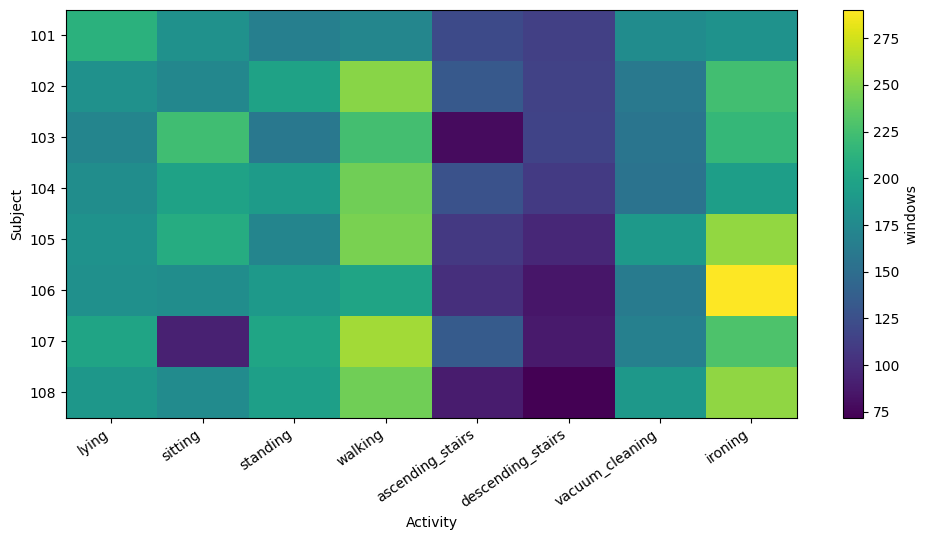

# FedVocabHAR PAMAP2 Phase 4A Data Report

**Proceed to Phase 4B:** True

- Cache shape: (11122, 4, 128)
- Minimum subject/activity windows: 72
- Locked policy: ranked_mnn

## Gates

- G1_all_eight_subjects_present: **True**
- G2_all_eight_activities_present: **True**
- G3_complete_subject_activity_grid: **True**
- G4_minimum_windows: **True**
- G5_finite_cache: **True**
- G6_cache_shape: **True**
- G7_cache_roundtrip: **True**
- G8_folds_valid: **True**
- G9_policy_lock_present: **True**

No PAMAP2 result may change the locked ranked-MNN policy.



In [7]:
counts=pd.crosstab(pd.Series(subjects,name='subject'),pd.Series(activities,name='activity')).reindex(index=CFG.subjects,columns=CFG.known_activities+CFG.novel_activities,fill_value=0);counts.to_csv(OUT/'phase4a_window_counts.csv');display(counts)
cache=np.load(CACHE/'pamap2_hand_acc_common8_w128_s64_50hz.npz');fold_valid=True
for fold in folds:
    roles=[set(fold[k]) for k in ('train_subjects','selection_subjects','integration_subjects','test_subjects')];fold_valid=fold_valid and set.union(*roles)==set(CFG.subjects) and all(roles[i].isdisjoint(roles[j]) for i in range(4) for j in range(i+1,4))
gates={'G1_all_eight_subjects_present':set(np.unique(subjects))==set(CFG.subjects),'G2_all_eight_activities_present':set(np.unique(activities))==set(CFG.known_activities+CFG.novel_activities),'G3_complete_subject_activity_grid':bool((counts>0).all().all()),'G4_minimum_windows':bool(counts.min().min()>=CFG.minimum_windows_per_subject_activity),'G5_finite_cache':bool(np.isfinite(x).all()),'G6_cache_shape':bool(x.shape[1:]==(4,CFG.window_size)),'G7_cache_roundtrip':bool(cache['x'].shape==x.shape),'G8_folds_valid':bool(fold_valid),'G9_policy_lock_present':bool(policy_lock['locked_for_third_dataset'])}
proceed=bool(all(gates.values()));decision={'phase':'Phase 4A','dataset':'PAMAP2 common-protocol subset','gates':gates,'proceed_to_phase4b':proceed,'cache':str(CACHE/'pamap2_hand_acc_common8_w128_s64_50hz.npz'),'cache_shape':list(x.shape),'minimum_windows':int(counts.min().min()),'locked_policy':policy_lock['selected_policy']};(OUT/'phase4a_quality_decision.json').write_text(json.dumps(decision,indent=2));print(json.dumps(decision,indent=2))
fig, ax = plt.subplots(figsize=(10, 5.5))
im = ax.imshow(counts.values, aspect='auto', cmap='viridis')
ax.set_xticks(range(len(counts.columns)))
ax.set_xticklabels(counts.columns, rotation=35, ha='right')
ax.set_yticks(range(len(counts.index)))
ax.set_yticklabels(counts.index)
ax.set_xlabel('Activity')
ax.set_ylabel('Subject')
fig.colorbar(im, ax=ax, label='windows')
fig.tight_layout()
fig.savefig(OUT/'phase4a_window_coverage.png', dpi=180, bbox_inches='tight')
plt.show()
report=f"# FedVocabHAR PAMAP2 Phase 4A Data Report\n\n**Proceed to Phase 4B:** {proceed}\n\n- Cache shape: {tuple(x.shape)}\n- Minimum subject/activity windows: {counts.min().min()}\n- Locked policy: {policy_lock['selected_policy']}\n\n## Gates\n\n"
for k,v in gates.items():report+=f'- {k}: **{v}**\n'
report+='\nNo PAMAP2 result may change the locked ranked-MNN policy.\n';(OUT/'FedVocabHAR_PAMAP2_Phase4A_Data_Report.md').write_text(report);print(report)
assert proceed,'Phase 4A gates failed; inspect the audit before Phase 4B'


## Next step

If all gates pass, Phase 4B will train fold-local SSL-Full and Episodic Anchor models, then evaluate the locked ranked-MNN agreement policy exactly once on the PAMAP2 test subjects.
